# 01 · Understanding the claims before building a model
**DSC 411/511 graduate project · Venkat Repaka and Ritik Gaire**

This notebook explains the data. We ask what each row and column means, what is missing, and what looks strange. Then we join three outside sources to the claims: rain, hurricane tracks and Census data. Sections 8.6–8.8 show how the sources fit together and what each one adds.

**Path:** look at the data → find problems → choose a fix → combine the sources → plan fair tests.

**Course links:** lecture 03 (cleaning, encoding, transformation, sampling), lecture 04 (correlation, PCA), lectures 07 and 10 (fair validation). Every change has a reason. More rows, more columns or a harder method do not automatically give better evidence.

## 1. Begin with the study population
The original file includes many years. Our question concerns loss years 2020–2025. We inspect the file size and keep that period before making large copies. One claim ID identifies one record, not a permanent building or household.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow.parquet as pq
from IPython.display import display, Markdown
from project_utils import *
from data_dictionary import COLUMNS
pd.set_option('display.max_columns', 15)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
source = pq.ParquetFile(raw_path())
raw = pd.read_parquet(raw_path(), filters=[('yearOfLoss','>=',2020),('yearOfLoss','<=',2025)])
print(f'Rows in source file: {source.metadata.num_rows:,}')
print(f'Rows in study period: {len(raw):,}; columns: {raw.shape[1]}')
print(f'Unique claim IDs: {raw.id.nunique():,}')
print(f'Memory used by study table: {raw.memory_usage(deep=True).sum()/1e6:,.1f} MB')
display(raw[['id','yearOfLoss','state','occupancyType','amountPaidOnBuildingClaim']].head())

Rows in source file: 2,725,989
Rows in study period: 277,033; columns: 84
Unique claim IDs: 277,033


Memory used by study table: 785.3 MB


,id,yearOfLoss,state,occupancyType,amountPaidOnBuildingClaim
0,5448679,2024,FL,18,500000.00
1,5448693,2022,FL,15,243827.07
2,5448700,2022,KY,14,13920.08
3,5448739,2024,FL,11,89984.55
4,5448757,2021,LA,11,52700.20


### 1.1 Read types before treating every number as a measurement
A state or foundation code is a label. Its number does not measure an amount. Money and age have meaningful sizes. CRS class has an order, but equal class steps do not necessarily mean equal risk changes. Dates also need conversion before subtraction.

In [2]:
types = pd.DataFrame([(c,str(raw[c].dtype),*COLUMNS.get(c,('No description retained','review needed')))
                      for c in raw.columns],columns=['field','storage type','meaning','attribute type']).set_index('field')
with pd.option_context('display.max_rows',100,'display.max_colwidth',90):
    display(types)
display(types['attribute type'].value_counts().to_frame('columns'))
save_table(types,'01_data_dictionary')

,storage type,meaning,attribute type
field,,,
agricultureStructureIndicator,bool,Building is an agricultural structure,binary
asOfDate,"datetime64[us, UTC]",Date the record was last updated by FEMA,interval
basementEnclosureCrawlspaceType,float64,"Code for basement, enclosure or crawlspace type",nominal
policyCount,int16,Number of insured units under the policy,ratio
crsClassCode,float64,"Community Rating System class (1 = best flood protection, 10 = none)",ordinal
dateOfLoss,object,Date the flood water first entered the building,interval
elevatedBuildingIndicator,bool,Building is elevated (NFIP definition),binary
elevationCertificateIndicator,object,Code for how the elevation certificate was used in rating,nominal
elevationDifference,float64,"Lowest floor minus base flood elevation, in feet",interval


,columns
attribute type,
nominal,29
ratio,24
interval,16
binary,12
ordinal,3


**What we learned.** Storage type and meaning are different. We will one-hot encode nominal codes, preserve an ordered CRS measure with caution, and treat dates and money as measurements. The dictionary is a summary of [FEMA's field documentation](https://www.fema.gov/openfema-data-page/fima-nfip-redacted-claims-v3); it is not evidence that every recorded value is correct.

### 1.2 Convert dates and money in an exploration copy
Some amounts are stored as Decimal values. We convert the fields needed for these checks. We keep `raw` unchanged so that the effect of cleaning remains visible.

Dates before 1800 are not usable building or claim dates in this study. We mark them missing before subtracting dates; otherwise a very old erroneous date can even overflow the date calculation.

In [3]:
work = raw.copy()
money = ['amountPaidOnBuildingClaim','amountPaidOnContentsClaim','netBuildingPaymentAmount',
         'buildingDamageAmount','buildingPropertyValue','buildingReplacementCost',
         'totalBuildingInsuranceCoverage','totalContentsInsuranceCoverage']
for col in money:
    work[col]=pd.to_numeric(work[col],errors='coerce').astype(float)
for col in ['dateOfLoss','openDate','originalConstructionDate','originalNBDate','mostRecentPaymentDate','asOfDate']:
    work[col]=pd.to_datetime(work[col].astype(str),errors='coerce')
    work[col]=work[col].where(work[col].dt.year>=1800)
print('Latest recorded update:',work.asOfDate.max().date())
display(work[money].describe(percentiles=[.01,.5,.9,.99]).T.round(1))

Latest recorded update: 2026-09-08


,count,mean,std,min,1%,50%,90%,99%,max
amountPaidOnBuildingClaim,"255,289.000","63,777.600","141,643.800","-2,250,000.000",0.000,"23,908.400","157,881.800","500,000.000","10,741,476.900"
amountPaidOnContentsClaim,"255,289.000","8,903.900","25,606.800","-80,000.000",0.000,0.000,"28,317.700","100,000.000","757,049.000"
netBuildingPaymentAmount,"277,033.000","58,734.400","137,012.800","-2,250,000.000",0.000,"18,256.700","150,729.000","488,475.800","10,741,476.900"
buildingDamageAmount,"246,461.000","68,031.500","215,136.800",0.000,0.000,"26,926.000","157,829.000","523,352.200","52,840,990.000"
buildingPropertyValue,"246,461.000","592,526.500","4,446,314.100",0.000,0.000,"204,166.000","684,729.000","7,388,194.600","526,308,898.000"
buildingReplacementCost,"246,461.000","823,647.200","8,593,965.400",0.000,0.000,"266,230.000","886,785.000","9,906,102.600","1,673,931,037.000"
totalBuildingInsuranceCoverage,"277,033.000","414,004.700","2,320,315.500",0.000,0.000,"250,000.000","258,000.000","5,000,000.000","272,500,000.000"
totalContentsInsuranceCoverage,"277,032.000","52,286.400","64,571.200",0.000,0.000,"40,000.000","100,000.000","426,000.000","500,000.000"


## 2. Which fields are missing, and does the reason matter?
Lecture 03 compared dropping, estimating and retaining missing values. We first measure the cost of dropping all rows with any blank. This is a demonstration, not the cleaning rule for our project.

Rows if every blank caused deletion: 0 of 277,033
Columns with no blanks: 27 of 84


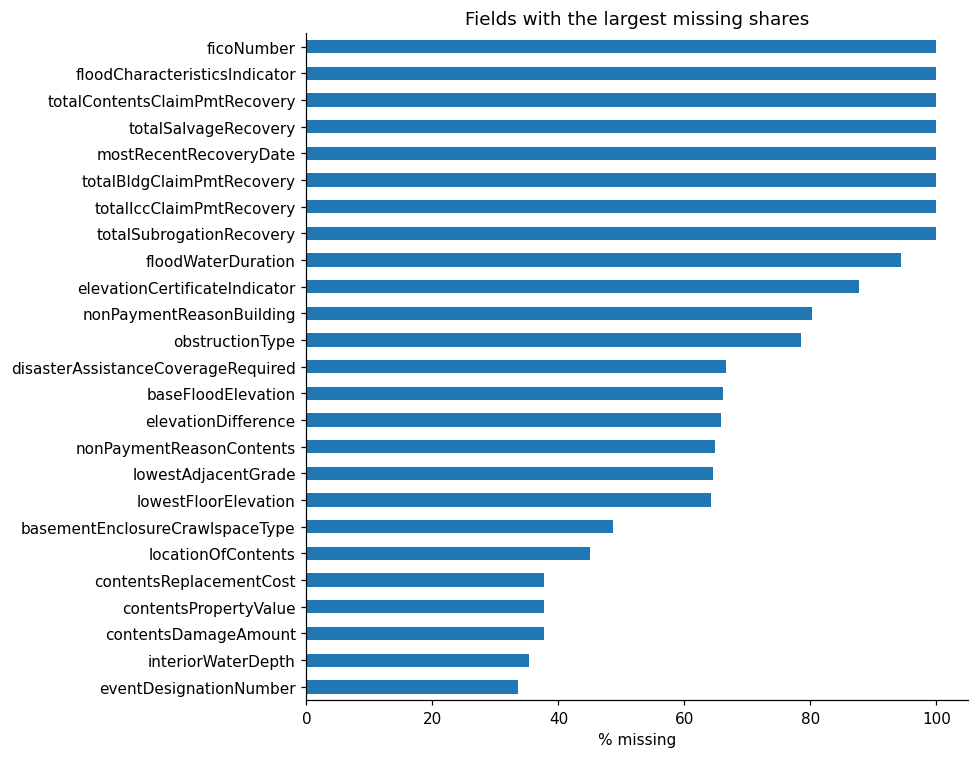

In [4]:
missing=work.isna().mean().sort_values(ascending=False)
print(f'Rows if every blank caused deletion: {len(work.dropna()):,} of {len(work):,}')
print(f'Columns with no blanks: {missing.eq(0).sum()} of {len(missing)}')
missing.head(25).sort_values().mul(100).plot.barh(figsize=(9,7),title='Fields with the largest missing shares')
plt.xlabel('% missing');plt.tight_layout();plt.show()
save_table(missing.to_frame('missing share'),'01_missing_fields')

**Decision.** We discard the rule “drop every row with a blank.” Some fields are absent for almost everyone or are not needed for a question. Each research question will define its own required outcome and predictors.

### 2.1 Do fields go missing together?
We turn each blank into 1 and each recorded value into 0, then correlate these indicators. If several fields are missing in the same rows, they may come from the same collection step. Correlation of blanks does not prove why they are missing.

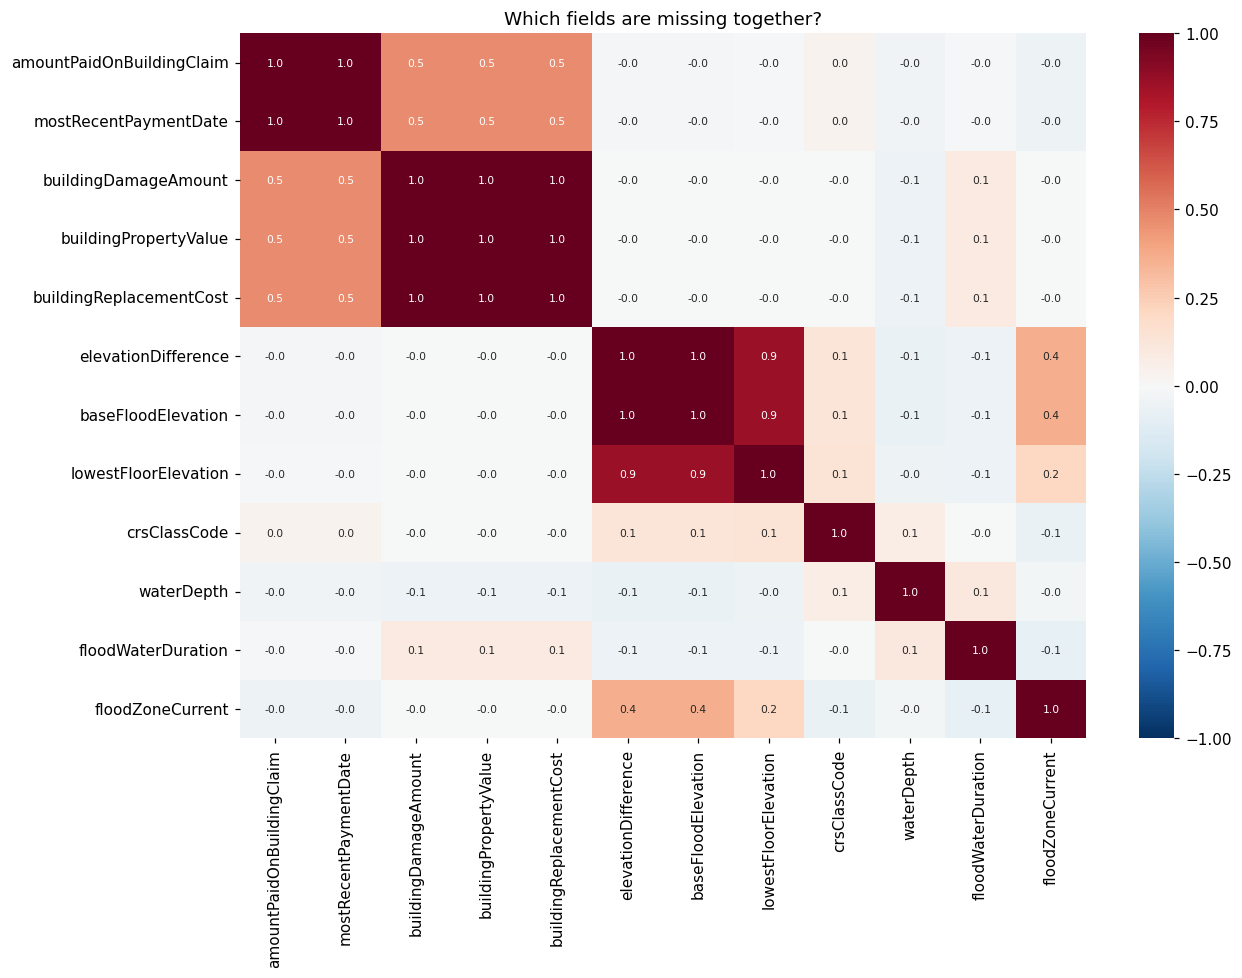

In [5]:
blank_cols=['amountPaidOnBuildingClaim','mostRecentPaymentDate','buildingDamageAmount','buildingPropertyValue',
            'buildingReplacementCost','elevationDifference','baseFloodElevation','lowestFloorElevation',
            'crsClassCode','foundationType','waterDepth','floodWaterDuration','floodZoneCurrent']
blank=work[blank_cols].isna().astype(int)
usable=blank.columns[blank.nunique()>1]
plt.figure(figsize=(12,9))
sns.heatmap(blank[usable].corr(),vmin=-1,vmax=1,cmap='RdBu_r',annot=True,fmt='.1f',annot_kws={'size':7})
plt.title('Which fields are missing together?');plt.tight_layout();plt.show()

### 2.2 Check a visible explanation before inventing a value
We compare years, rating systems and recorded payment status. A different blank rate suggests that collection or claim processing matters. It does not establish that missingness is random within each group.

In [6]:
work['rating_group']=np.where(work.rateMethod.eq('RE'),'Risk Rating 2.0','legacy / other')
work['payment_status']=np.select([work.amountPaidOnBuildingClaim.isna(),work.amountPaidOnBuildingClaim.eq(0)],
                               ['missing','zero'],default='nonzero')
focus=['buildingDamageAmount','buildingReplacementCost','elevationDifference','crsClassCode']
for label,group in [('loss year',work.yearOfLoss),('rating group',work.rating_group),('payment status',work.payment_status)]:
    print(label)
    display(work[focus].isna().groupby(group).mean().mul(100).round(1))

loss year


,buildingDamageAmount,buildingReplacementCost,elevationDifference,crsClassCode
yearOfLoss,,,,
2020,13.200,13.200,56.900,44.800
2021,9.500,9.500,67.900,54.300
2022,13.300,13.300,46.100,17.100
2023,12.700,12.700,75.900,36.700
2024,9.500,9.500,75.300,15.700
2025,9.800,9.800,82.200,60.100


rating group


,buildingDamageAmount,buildingReplacementCost,elevationDifference,crsClassCode
rating_group,,,,
Risk Rating 2.0,10.900,10.900,65.200,25.900
legacy / other,12.200,12.200,71.200,64.200


payment status


,buildingDamageAmount,buildingReplacementCost,elevationDifference,crsClassCode
payment_status,,,,
missing,61.700,61.700,63.100,35.700
nonzero,0.500,0.500,66.600,29.300
zero,38.300,38.300,63.700,29.100


### 2.3 “Not applicable” differs from “not recorded”
A recovery date may not exist when no money was recovered. Missing contents information may relate to a policy without contents cover. We check those relationships; we do not automatically turn missing damage or payment into zero.

In [7]:
no_contents=pd.to_numeric(work.totalContentsInsuranceCoverage,errors='coerce').fillna(0).eq(0)
display(work.groupby(no_contents).agg(claims=('id','size'),
    contents_damage_missing=('contentsDamageAmount',lambda s:s.isna().mean()),
    contents_deductible_missing=('contentsDeductibleCode',lambda s:s.isna().mean())))
recovery=pd.to_numeric(work.totalBldgClaimPmtRecovery,errors='coerce').fillna(0)
display(work.groupby(recovery.gt(0)).agg(claims=('id','size'),
    recovery_date_missing=('mostRecentRecoveryDate',lambda s:s.isna().mean())))

,claims,contents_damage_missing,contents_deductible_missing
totalContentsInsuranceCoverage,,,
False,195888,0.217,0.000
True,81145,0.765,0.973


,claims,recovery_date_missing
totalBldgClaimPmtRecovery,,
False,276717,1.000
True,316,0.000


**Decision.** Missing outcomes stay missing. A missing predictor can be estimated from fitting data, with a flag when useful. We do not claim that group comparisons identify a complete missing-data mechanism. If an unrecorded inspection or dispute matters, the observed sample may still be selected.

### 2.4 A recorded code can still mean missing information
A blank cell is not the only missing-data representation. We count empty text markers and review several special numeric codes. Code 0 means “not recorded” for foundation, but deductible code 0 maps to a $500 deductible. Replacing every zero with missing would damage the data.

The depth value 99 is shown as a screening example only. Depth units and special codes need field documentation; we do not use these uncertain post-inspection depth fields in the main early-predictor models.

In [8]:
marker_rows=[]
for col in ['reportedCity','ratedFloodZone','foundationType','occupancyType','buildingDeductibleCode']:
    text=work[col].astype('string').str.strip().str.upper()
    marker_rows.append({'field':col,'actual blank':work[col].isna().sum(),
                        'recorded empty/text marker':(work[col].notna()&text.isin(['','NULL','NAN','NONE','<NA>'])).sum()})
display(pd.DataFrame(marker_rows).set_index('field'))
display(pd.Series({
    'foundation code 0 (not recorded)':code(work.foundationType).eq('0').sum(),
    'deductible code 0 ($500)':code(work.buildingDeductibleCode).eq('0').sum(),
    'depth value 99 (review meaning)':pd.to_numeric(work.waterDepth,errors='coerce').eq(99).sum(),
    'base elevation absolute >=9000':pd.to_numeric(work.baseFloodElevation,errors='coerce').abs().ge(9000).sum()
}).to_frame('records'))


,actual blank,recorded empty/text marker
field,,
reportedCity,0,0
ratedFloodZone,53,0
foundationType,0,0
occupancyType,0,0
buildingDeductibleCode,6774,0


,records
foundation code 0 (not recorded),26194
deductible code 0 ($500),1
depth value 99 (review meaning),12509
base elevation absolute >=9000,968


## 3. Similar records, outliers and errors are different problems
### 3.1 Decide what “duplicate” means
Two redacted claims can share rounded coordinates and the same amounts. Different IDs may still represent different claims. This differs from an exact repeated record with the same ID.

In [9]:
print('Repeated claim IDs:',work.id.duplicated().sum())
print('Exact duplicate rows:',raw.duplicated().sum())
non_id=[c for c in raw if c!='id']
print('Matching rows after removing ID:',raw.duplicated(subset=non_id).sum())
similar=raw.duplicated(subset=non_id,keep=False)
display(work.loc[similar,['id','yearOfLoss','state','latitude','longitude','amountPaidOnBuildingClaim']].head(8))

Repeated claim IDs: 0


Exact duplicate rows: 0


Matching rows after removing ID: 453


,id,yearOfLoss,state,latitude,longitude,amountPaidOnBuildingClaim
1511,5463075,2020,FL,26.4,-82.0,0.000
1567,5463674,2024,FL,28.1,-82.8,0.000
1617,5464262,2022,FL,26.5,-81.9,NaN
2785,5476379,2022,FL,26.5,-81.9,NaN
3119,5479587,2024,FL,28.0,-82.6,0.000
3215,5480514,2022,FL,26.4,-81.8,0.000
3686,5485221,2024,FL,26.5,-81.9,NaN
5259,5500820,2024,FL,27.3,-82.6,0.000


**Decision.** Keep unique claim IDs. We report similar redacted records as a review issue. Deleting them without evidence could remove genuine claims. This corrects the earlier project rule that deleted matches across all non-ID fields.

### 3.2 Find possible errors with cross-field rules
We count suspicious values before applying a fix. A date after the loss can have more than one explanation: construction after loss is inconsistent with the recorded damaged building, but a policy's later record may reflect an update.

In [10]:
age=(work.dateOfLoss-work.originalConstructionDate).dt.days/365.25
lag=(work.openDate-work.dateOfLoss).dt.days
noise=pd.Series({'negative building payment':work.amountPaidOnBuildingClaim.lt(0).sum(),
                 'construction date after loss':age.lt(0).sum(),
                 'opening date before loss':lag.lt(0).sum(),
                 'policy start field after loss':work.originalNBDate.gt(work.dateOfLoss).sum(),
                 'elevation difference absolute >=500':pd.to_numeric(work.elevationDifference,errors='coerce').abs().ge(500).sum()})
display(noise.to_frame('records to review'))

,records to review
negative building payment,35
construction date after loss,90
opening date before loss,56
policy start field after loss,6339
elevation difference absolute >=500,13


**Decision.** Mark negative payments, negative building ages and negative reporting lags missing for the affected analysis. Retain the original fields for review. Extremely large elevation placeholders are excluded from elevation analysis. We do not use policy start dates to infer coverage at the loss because the record may have been updated.

### 3.3 The largest payments may be valid condominium losses
The IQR rule marks values above Q3 + 1.5 × IQR. It identifies unusual values, not confirmed errors. We compare the large claims with coverage and policy count before deciding what to retain.

In [11]:
pay=work.loc[work.amountPaidOnBuildingClaim.gt(0),'amountPaidOnBuildingClaim']
q1,q3=pay.quantile([.25,.75]);fence=q3+1.5*(q3-q1)
large=work[work.amountPaidOnBuildingClaim>fence]
print(f'IQR upper fence: ${fence:,.0f}; flagged paid claims: {len(large):,} ({len(large)/len(pay):.1%})')
print('Share of flagged payments within recorded coverage:',(large.amountPaidOnBuildingClaim<=large.totalBuildingInsuranceCoverage+1).mean())
display(work.nlargest(8,'amountPaidOnBuildingClaim')[['amountPaidOnBuildingClaim','totalBuildingInsuranceCoverage','policyCount','numberOfUnits','occupancyType','state']])

IQR upper fence: $234,872; flagged paid claims: 11,718 (5.5%)
Share of flagged payments within recorded coverage: 0.989247311827957


,amountPaidOnBuildingClaim,totalBuildingInsuranceCoverage,policyCount,numberOfUnits,occupancyType,state
71740,"10,741,476.930","49,500,000.000",198,198.000,15,FL
98342,"10,493,402.340","13,500,000.000",54,54.000,15,FL
236283,"9,000,000.000","9,000,000.000",36,36.000,15,FL
105155,"8,758,773.330","12,032,000.000",72,72.000,15,FL
167707,"7,778,936.860","12,750,000.000",51,51.000,15,FL
228190,"6,578,657.200","12,876,000.000",72,72.000,15,FL
133797,"6,283,274.240","23,500,000.000",94,94.000,15,FL
13959,"6,000,000.000","6,000,000.000",24,24.000,15,FL


### 3.4 Change the scale before deleting the tail
We plot the same positive payments on dollar and log scales. A log scale gives small and large claims room on the page. It does not remove records or guarantee a better model.

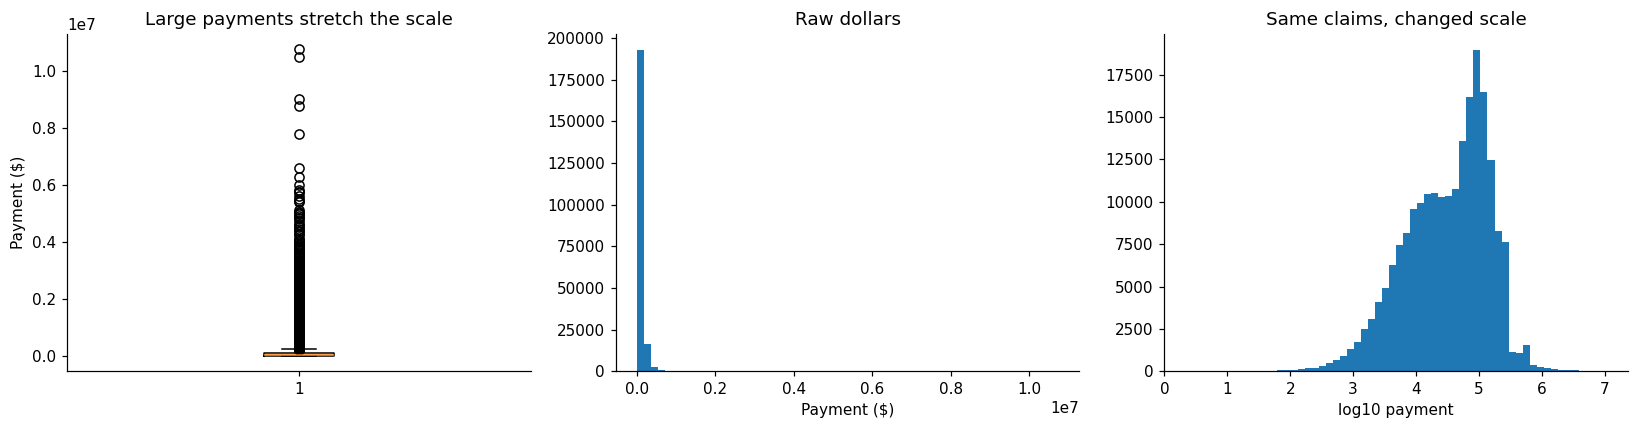

In [12]:
fig,ax=plt.subplots(1,3,figsize=(15,4))
ax[0].boxplot(pay);ax[0].set(ylabel='Payment ($)',title='Large payments stretch the scale')
ax[1].hist(pay,bins=60);ax[1].set(xlabel='Payment ($)',title='Raw dollars')
ax[2].hist(np.log10(pay),bins=60);ax[2].set(xlabel='log10 payment',title='Same claims, changed scale')
plt.tight_layout();plt.show()

**Decision.** Retain the large claims and compare models with both typical and large-loss errors. A low median error can hide mistakes on large buildings. We will test a log target and payment as a share of coverage in notebook 02, rather than assuming one transformation must work.

## 4. Apply and audit the preparation rules
The shared preparation function implements the stated rules and saves the common table. It preserves missing outcomes. No median or model-based predictor imputation is saved here, because a future fitting split must learn its own replacements.

In [13]:
df=clean_claims()
assert df.id.is_unique and len(df)==len(raw)
assert set(df.id)==set(raw.id)
audit=pd.Series({'retained claims':len(df),'negative payments marked missing':df.negative_payment_flag.sum(),
                 'negative ages marked missing':age.lt(0).sum(),'damage above building value':df.ratio_above_one_flag.sum(),
                 'known zero payments':df.amountPaidOnBuildingClaim.eq(0).sum(),
                 'missing payments':df.amountPaidOnBuildingClaim.isna().sum()})
display(audit.to_frame('count'))
print('Saved:',DATA/'claims_clean.parquet')

,count
retained claims,277033
negative payments marked missing,35
negative ages marked missing,90
damage above building value,1580
known zero payments,42288
missing payments,21779


Saved: /Users/home/workspace/School/DataMining/nfip_claims_project/student_notebooks/data/claims_clean.parquet


### 4.1 Damage, payment and the damage ratio answer different questions
Payment is money recorded as paid. Damage is the adjuster's damage estimate. The ratio divides damage by reported building value. A large dollar loss can belong to a big building with a moderate ratio.

In [14]:
display(df[['amountPaidOnBuildingClaim','buildingDamageAmount','buildingPropertyValue','damage_ratio_raw','damage_ratio']].describe(percentiles=[.5,.9,.99]).T.round(3))
print('Damage ratios excluded from main 0–1 charts:',df.ratio_above_one_flag.sum())
display(df.groupby('occupancy_name').agg(claims=('id','size'),median_damage=('buildingDamageAmount','median'),
    median_ratio=('damage_ratio','median'),ratio_available=('damage_ratio',lambda s:s.notna().mean())).round(3))

,count,mean,std,min,50%,90%,99%,max
amountPaidOnBuildingClaim,"255,254.000","63,801.864","141,571.862",0.000,"23,917.950","157,895.175","500,000.000","10,741,476.930"
buildingDamageAmount,"246,461.000","68,031.536","215,136.818",0.000,"26,926.000","157,829.000","523,352.200","52,840,990.000"
buildingPropertyValue,"246,461.000","592,526.472","4,446,314.065",0.000,"204,166.000","684,729.000","7,388,194.600","526,308,898.000"
damage_ratio_raw,"218,614.000",0.299,4.396,0.000,0.143,0.622,1.000,"1,040.104"
damage_ratio,"217,034.000",0.243,0.249,0.000,0.140,0.609,0.965,1.000


Damage ratios excluded from main 0–1 charts: 1580


,claims,median_damage,median_ratio,ratio_available
occupancy_name,,,,
2-4 units,11153,"33,334.500",0.164,0.831
5+ units,5090,"59,737.000",0.076,0.782
condo building,16246,"61,867.500",0.081,0.818
mobile home,6305,"17,439.000",0.412,0.763
non-res. mobile,80,"6,921.000",0.329,0.775
non-res. unit,204,0.000,0.032,0.025
non-residential,20184,"40,269.000",0.098,0.752
single family,209676,"25,138.000",0.147,0.803
unit in building,8095,0.000,0.017,0.260


**Decision.** Ratios above 1 are discrepancies requiring review, not proven impossible losses. We preserve the raw ratio and exclude them from main 0–1 severity plots. Notebook 09 checks sensitivity to its payment-share definition. Notebook 10 deliberately includes financial discrepancies in anomaly review.

## 5. Learn from the claim mix before fitting a model
### 5.1 Years and months
Counts show which events dominate our sample. They do not measure the probability that an insured building floods, because the dataset does not include every insured building.

,claims,paid_claims,median_paid
loss_year,,,
2020,33185,24011,"14,032.000"
2021,46699,34729,"23,620.000"
2022,60262,44762,"56,000.000"
2023,21690,16270,"31,549.000"
2024,102054,82737,"68,062.000"
2025,13143,10457,"28,955.000"


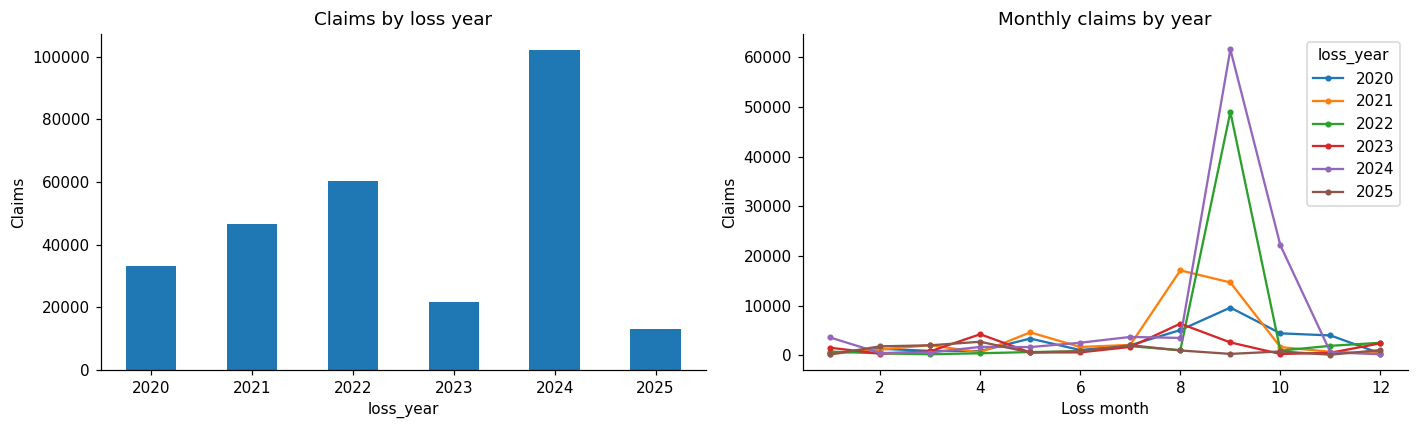

In [15]:
by_year=df.groupby('loss_year').agg(claims=('id','size'),paid_claims=('amountPaidOnBuildingClaim',lambda s:s.gt(0).sum()),
                                  median_paid=('amountPaidOnBuildingClaim',lambda s:s[s>0].median()))
display(by_year.round(0))
fig,ax=plt.subplots(1,2,figsize=(13,4))
by_year.claims.plot.bar(ax=ax[0],title='Claims by loss year');ax[0].set_ylabel('Claims');ax[0].tick_params(axis='x',rotation=0)
pd.crosstab(df.loss_month,df.loss_year).plot(ax=ax[1],marker='.',title='Monthly claims by year')
ax[1].set(xlabel='Loss month',ylabel='Claims');plt.tight_layout();plt.show()

### 5.2 A few named events provide many rows
A random row split can place the same hurricane in fitting and evaluation data. Similar conditions on both sides can make a model look more general than it is. Notebook 02 will compare row-based and event-based validation before using later years.

,claims
floodEvent,
Hurricane Helene,58090
no named event,56474
Hurricane Ian,48824
Hurricane Ida,28318
Hurricane Milton,21675
Hurricane Sally,8120
Hurricane Idalia,5522
Hurricane Eta,3677
April Florida Flooding,3443


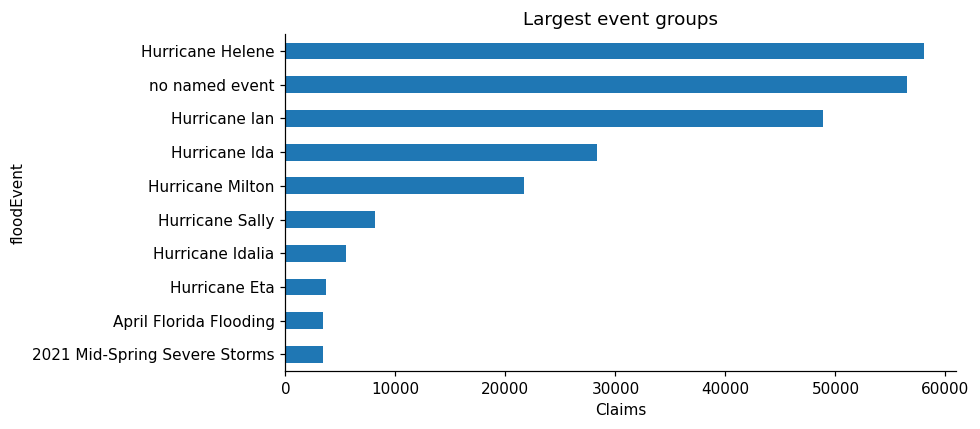

Share from four largest named events: 0.5663837882129565


In [16]:
events=df.floodEvent.fillna('no named event').value_counts()
display(events.head(12).to_frame('claims'))
events.head(10).sort_values().plot.barh(figsize=(9,4),title='Largest event groups')
plt.xlabel('Claims');plt.tight_layout();plt.show()
print('Share from four largest named events:',df.floodEvent.value_counts().head(4).sum()/len(df))

### 5.3 Place: counts and damage tell different stories
Florida has many observed claims. Other states can still have high damage among their claims. A state ranking without the number of exposed or insured buildings is not a flood-risk rate.

,claims,median_ratio,median_paid
state,,,
FL,152716,0.276,"71,089.800"
LA,28618,0.153,"36,620.690"
TX,13216,0.102,"25,461.345"
NJ,11089,0.076,"19,005.530"
NY,9276,0.053,"16,669.740"
NC,7038,0.074,"18,059.210"
AL,4765,0.049,"14,386.935"
PA,4757,0.081,"17,364.120"
KY,3895,0.131,"22,641.420"


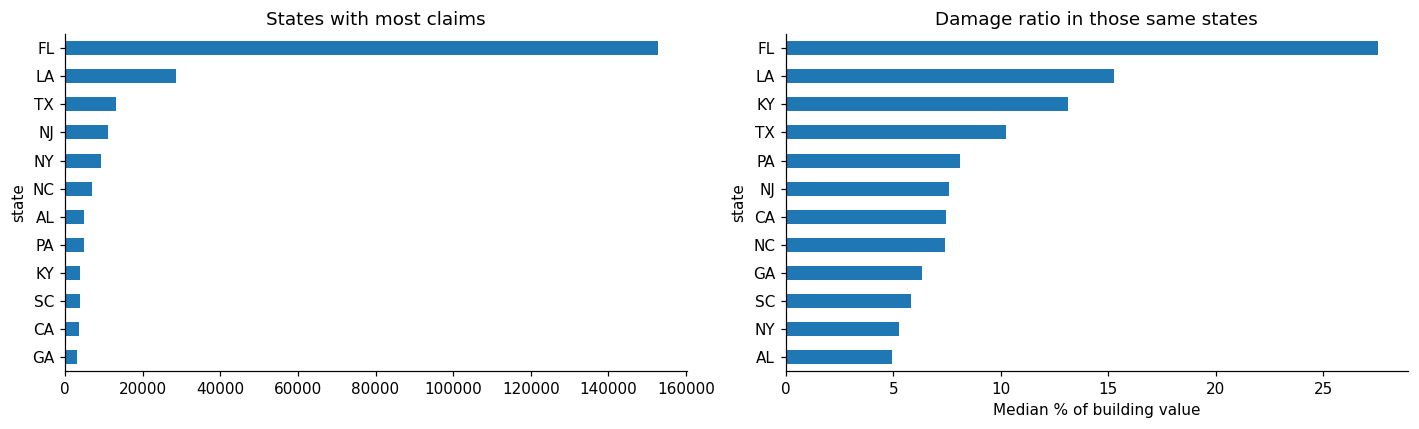

In [17]:
state=df.groupby('state').agg(claims=('id','size'),median_ratio=('damage_ratio','median'),
    median_paid=('amountPaidOnBuildingClaim',lambda s:s[s>0].median()))
display(state.sort_values('claims',ascending=False).head(15).round(3))
fig,ax=plt.subplots(1,2,figsize=(13,4))
state.nlargest(12,'claims').claims.sort_values().plot.barh(ax=ax[0],title='States with most claims')
state.nlargest(12,'claims').median_ratio.sort_values().mul(100).plot.barh(ax=ax[1],title='Damage ratio in those same states')
ax[1].set_xlabel('Median % of building value');plt.tight_layout();plt.show()

### 5.3.1 View the recorded spatial concentration
This is a coordinate plot of claims in the approximate lower-48 range, not a street map or an exposure-adjusted risk map. Each point combines claims sharing FEMA's rounded coordinates. Several properties can occupy the same point; we cannot use it as a property identifier.

The coarse pattern helps explain why local rain and hurricane matching are approximate. The later joins use a block-group center where available, then rounded coordinates as a fallback.

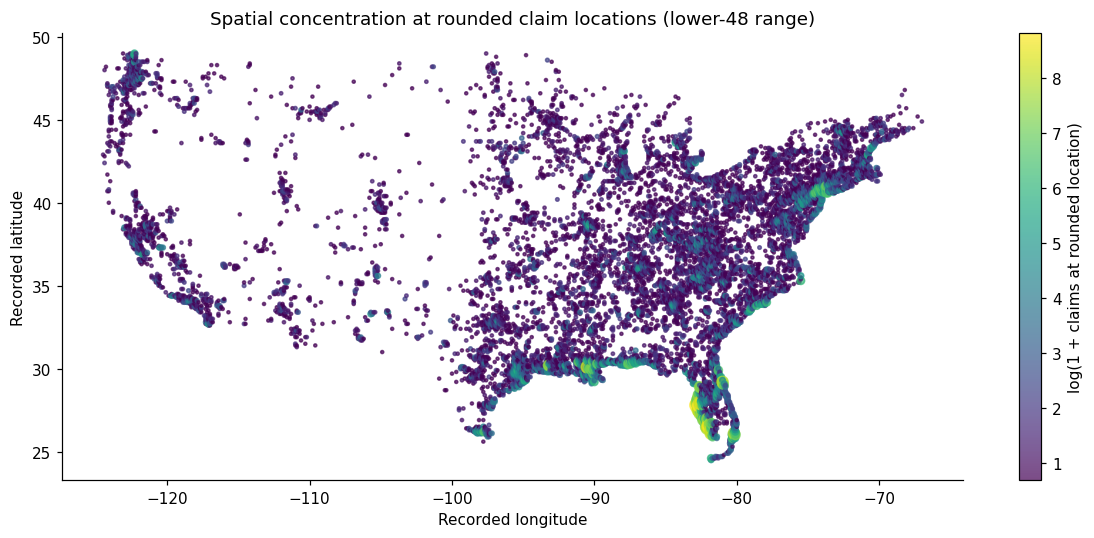

In [18]:
geo=df[df.latitude.between(24,50)&df.longitude.between(-125,-65)].groupby(['longitude','latitude']).size().rename('claims').reset_index()
plt.figure(figsize=(11,5))
points=plt.scatter(geo.longitude,geo.latitude,c=np.log1p(geo.claims),s=3+np.sqrt(geo.claims),cmap='viridis',alpha=.7)
plt.colorbar(points,label='log(1 + claims at rounded location)')
plt.xlabel('Recorded longitude');plt.ylabel('Recorded latitude');plt.title('Spatial concentration at rounded claim locations (lower-48 range)')
plt.tight_layout();plt.show()


### 5.4 Foundation and flood zone
We compare categories before asking a clustering algorithm to invent new groups. If one existing feature already describes damage differences well, a new cluster label must show added value.

,claims,known_ratio,median_ratio
foundation_name,,,
basement,24234,20420,0.056
crawlspace,20267,16849,0.110
elevated (4),16748,13080,0.087
elevated (5),19347,16321,0.032
elevated (6),16380,13523,0.033
not recorded,26194,20068,0.089
slab,153863,116773,0.301


,claims,known_ratio,median_ratio
zone,,,
A,9816,7888,0.160
A99,985,738,0.162
AE,197362,157753,0.180
AH,4229,3241,0.130
AO,1639,1242,0.083
V,10868,8363,0.068
X,52020,37726,0.073
unknown,114,83,0.087


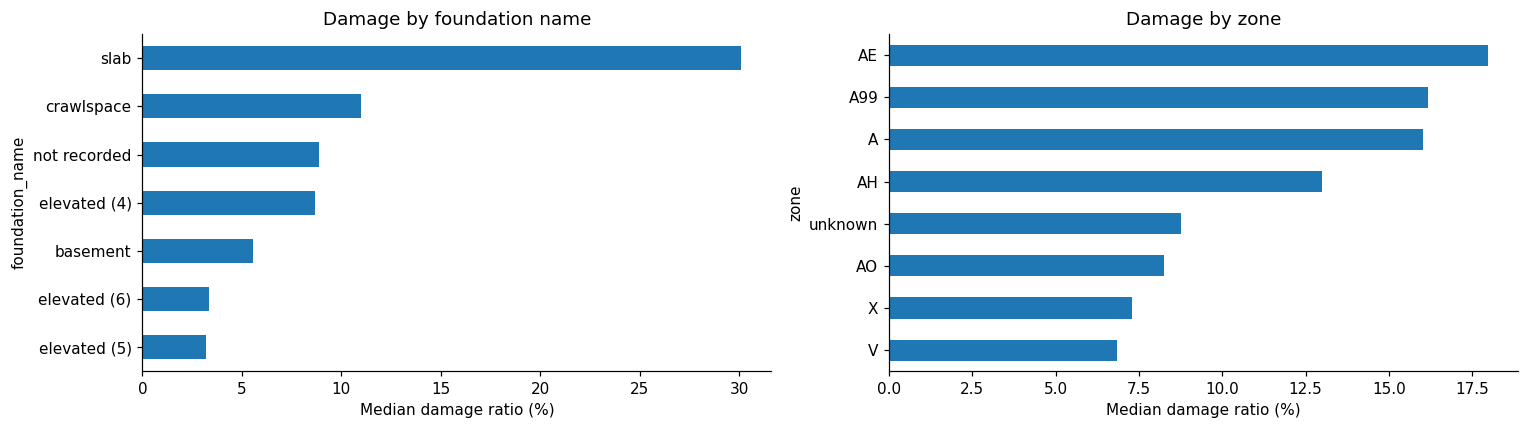

In [19]:
fig,ax=plt.subplots(1,2,figsize=(14,4))
for a,col in zip(ax,['foundation_name','zone']):
    table=df.groupby(col).agg(claims=('id','size'),known_ratio=('damage_ratio','count'),median_ratio=('damage_ratio','median'))
    display(table.round(3))
    table.median_ratio.mul(100).sort_values().plot.barh(ax=a,title=f'Damage by {col.replace("_"," ")}')
    a.set_xlabel('Median damage ratio (%)')
plt.tight_layout();plt.show()

### 5.5 Building age: compare the pattern with the sample size
Grouping continuous age into eras makes a chart readable, but it removes detail. We show counts beside damage ratios and retain continuous age for the main prediction models.

,claims,median_ratio
building_age,,
up to 20,33640,0.033
21–40,60757,0.058
41–60,105264,0.253
over 60,75050,0.181


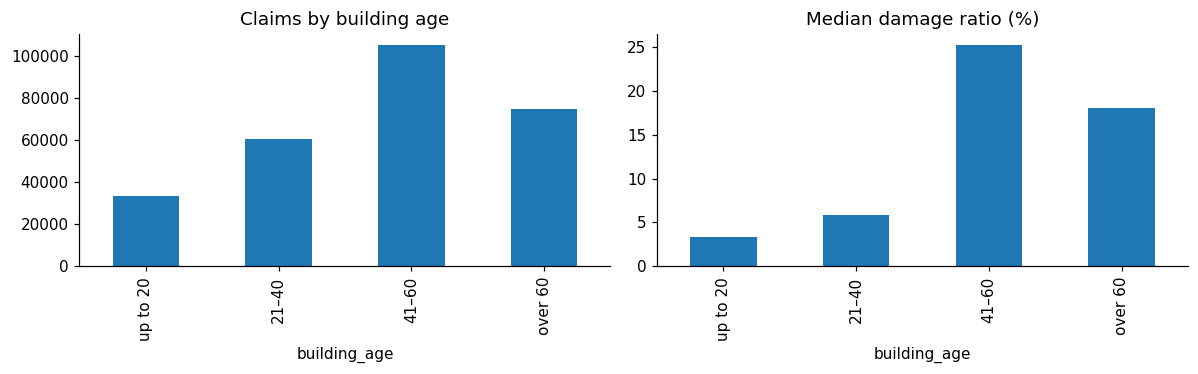

In [20]:
age_band=pd.cut(df.building_age,[-np.inf,20,40,60,np.inf],labels=['up to 20','21–40','41–60','over 60'])
ages=df.groupby(age_band,observed=True).agg(claims=('id','size'),median_ratio=('damage_ratio','median'))
display(ages.round(3))
fig,ax=plt.subplots(1,2,figsize=(11,3.5));ages.claims.plot.bar(ax=ax[0]);ages.median_ratio.mul(100).plot.bar(ax=ax[1])
ax[0].set_title('Claims by building age');ax[1].set_title('Median damage ratio (%)');plt.tight_layout();plt.show()

## 6. Correlation is useful, but leakage can make it misleading
### 6.1 A feature may predict well because it is recorded after the outcome
We compare policy variables with inspection and payment fields. We identify leakage from how a field is collected, not only from a correlation cutoff.

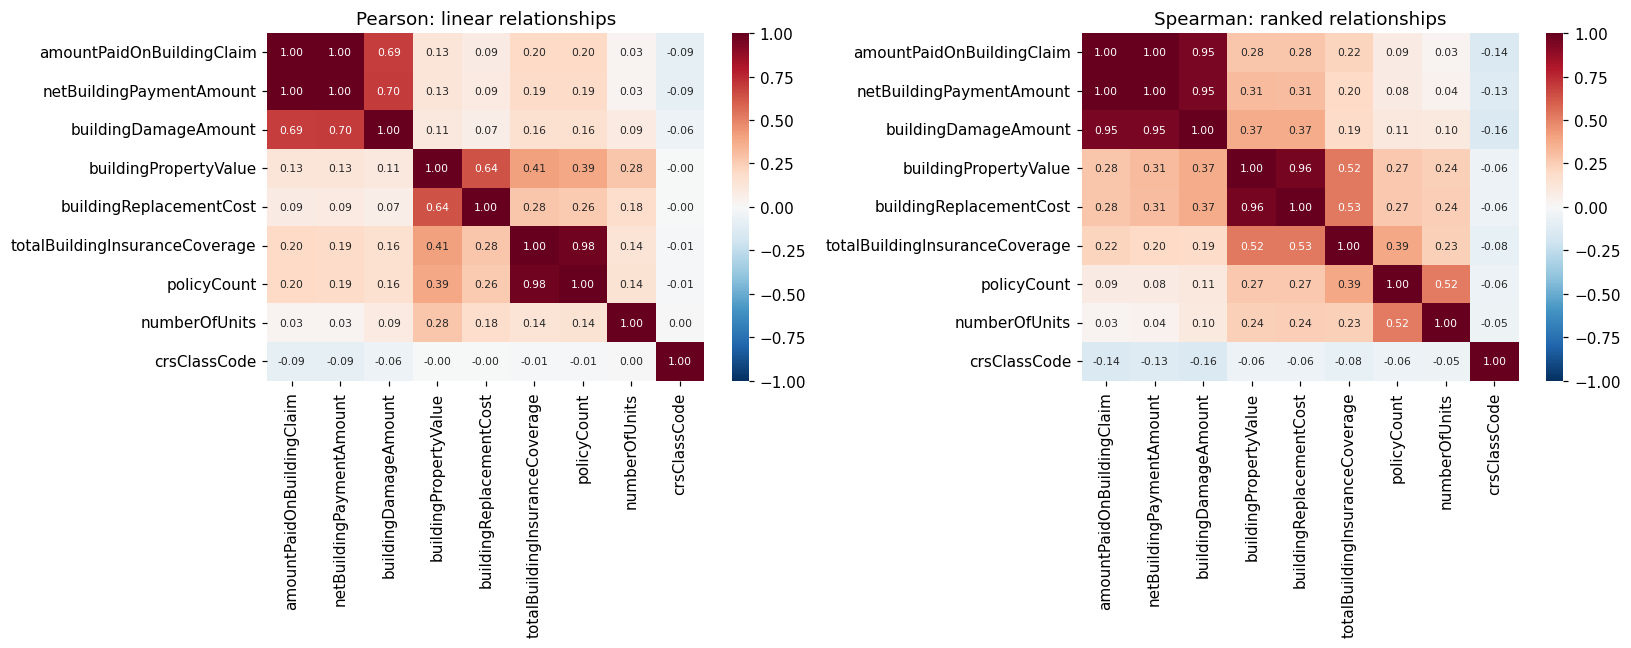

In [21]:
corr_cols=['amountPaidOnBuildingClaim','netBuildingPaymentAmount','buildingDamageAmount','buildingPropertyValue',
           'buildingReplacementCost','totalBuildingInsuranceCoverage','policyCount','numberOfUnits','crsClassCode']
num=work[corr_cols].apply(pd.to_numeric,errors='coerce')
fig,ax=plt.subplots(1,2,figsize=(15,6))
sns.heatmap(num.corr(),ax=ax[0],vmin=-1,vmax=1,cmap='RdBu_r',annot=True,fmt='.2f',annot_kws={'size':7})
sns.heatmap(num.corr(method='spearman'),ax=ax[1],vmin=-1,vmax=1,cmap='RdBu_r',annot=True,fmt='.2f',annot_kws={'size':7})
ax[0].set_title('Pearson: linear relationships');ax[1].set_title('Spearman: ranked relationships');plt.tight_layout();plt.show()

**Decision.** Exclude net payments, adjusted damage, property value, replacement cost, flood depth, non-payment reasons and payment dates from the main payment/severity predictors. They remain valid outcomes or descriptive inputs in clearly retrospective studies. A weak correlation does not make a post-loss field safe for an early prediction.

In [22]:
leakage=pd.DataFrame([
 ('Policy and building fields','Main predictors','Historical availability still needs checking'),
 ('Damage and adjusted property values','Outcomes / ratios','Recorded through inspection'),
 ('Payment amounts and latest payment date','Outcomes / retrospective analysis','Observed after opening'),
 ('Rain and HURDAT2 tracks','Retrospective event features','Windows include later days; tracks are revised'),
 ('ACS neighborhood estimates','Retrospective context','Five-year area estimates, not household facts')],columns=['group','use','reason'])
display(leakage)

,group,use,reason
0,Policy and building fields,Main predictors,Historical availability still needs checking
1,Damage and adjusted property values,Outcomes / ratios,Recorded through inspection
2,Payment amounts and latest payment date,Outcomes / retrospective analysis,Observed after opening
3,Rain and HURDAT2 tracks,Retrospective event features,Windows include later days; tracks are revised
4,ACS neighborhood estimates,Retrospective context,"Five-year area estimates, not household facts"


## 7. Compare preparation choices on fitting-period data
### 7.1 Median, grouped median or nearest-neighbor imputation?
Following lecture 03, we hide some known building ages within 2020–2021 and compare three ways to recover them. This is a small imputation exercise. It does not use later years or invent damage outcomes.

In [23]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
cols=['building_age','totalBuildingInsuranceCoverage','policyCount','crsClassCode']
example=df[df.loss_year.le(2021)&df[cols].notna().all(axis=1)].sample(4000,random_state=SEED).copy()
rng=np.random.default_rng(SEED);hide=rng.random(len(example))<.2
observed=example.loc[~hide];held=example.loc[hide]
global_pred=np.full(len(held),observed.building_age.median())
group_median=observed.groupby('foundation').building_age.median()
group_pred=held.foundation.map(group_median).fillna(observed.building_age.median()).to_numpy()
scaler=StandardScaler().fit(observed[cols])
imputer=KNNImputer(n_neighbors=5).fit(scaler.transform(observed[cols]))
masked=held[cols].copy();masked['building_age']=np.nan
knn_scaled=imputer.transform(scaler.transform(masked))
knn_pred=scaler.inverse_transform(knn_scaled)[:,0]
imputation=pd.DataFrame({name:{'age MAE (years)':np.abs(held.building_age.to_numpy()-pred).mean()}
 for name,pred in [('median',global_pred),('foundation median',group_pred),('scaled KNN',knn_pred)]}).T
display(imputation.round(2));save_table(imputation,'01_imputation_exercise')

,age MAE (years)
median,17.760
foundation median,16.080
scaled KNN,18.830


**What this test can tell us.** It compares recovery of artificially hidden ages. Real missing ages may have a different pattern. We keep training-only median imputation plus missing flags as the main simple preparation. Grouped or neighbor estimates need separate evidence that their extra complexity helps the research outcome. We never estimate missing payments to improve a prediction score.

### 7.2 Nominal encoding and scale
A foundation code of 6 is not six times a slab foundation. One-hot encoding makes separate columns. Distance methods then need attention to scale: a dollar difference can otherwise overwhelm a difference in age.

In [24]:
from sklearn.metrics import pairwise_distances
small=df[df.loss_year.le(2021)].sample(5,random_state=SEED)
display(small[['foundation','totalBuildingInsuranceCoverage','building_age']])
display(pd.get_dummies(small[['foundation']],dtype=int))
scale_cols=['totalBuildingInsuranceCoverage','building_age','policyCount']
scale_example=df.loc[df.loss_year.le(2021),scale_cols].dropna().sample(300,random_state=SEED)
raw_distance=pairwise_distances(scale_example.iloc[:1],scale_example).ravel();raw_distance[0]=np.inf
scale=StandardScaler().fit(scale_example);scaled=scale.transform(scale_example)
scaled_distance=pairwise_distances(scaled[:1],scaled).ravel();scaled_distance[0]=np.inf
print('Closest record using raw units:',int(raw_distance.argmin()))
print('Closest record after scaling:',int(scaled_distance.argmin()))
print('Different neighbors are possible because we changed the meaning of distance.')

,foundation,totalBuildingInsuranceCoverage,building_age
206710,0,0.000,96.665
4132,1,"35,000.000",55.671
145664,0,"100,000.000",36.348
12918,2,"250,000.000",97.114
178448,1,"250,000.000",23.127


,foundation_0,foundation_1,foundation_2
206710,1,0,0
4132,0,1,0
145664,1,0,0
12918,0,0,1
178448,0,1,0


Closest record using raw units: 183
Closest record after scaling: 246
Different neighbors are possible because we changed the meaning of distance.


**Decision.** Scale numeric predictors inside distance, linear and PCA pipelines. Tree splits do not require the same scaling. The example scaler is for explanation only; later model scalers are always fitted inside their own fitting split.

### 7.3 Equal-width bins, equal-frequency bins and meaningful bands
Lecture 03 showed that equal-width bins can leave most records in one group. We test that with positive payments from fitting years. Quantile bins describe this fitting distribution; fixed damage-ratio bands have a different, interpretable meaning.

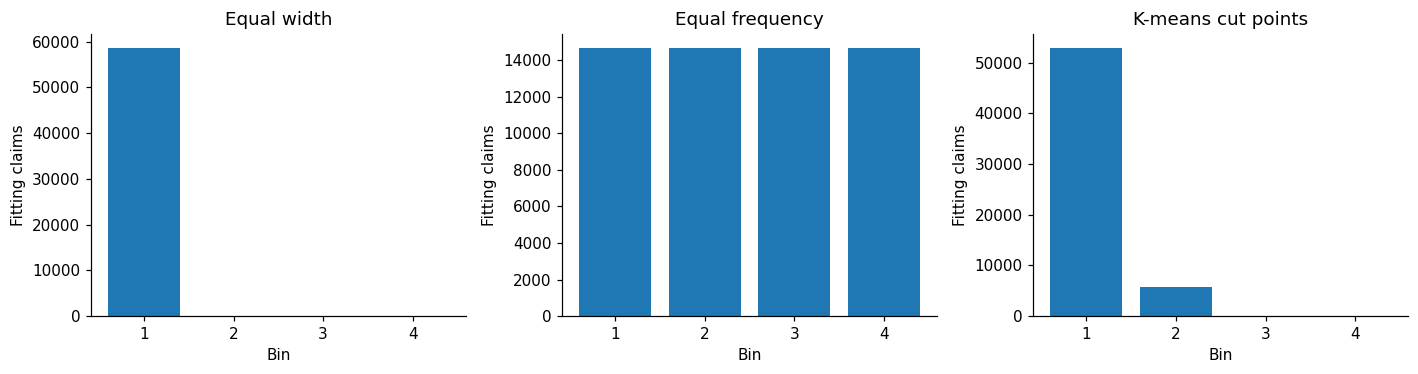

,claims
severity_band,
minor (0-10%),96132
NaN,59999
major (25-50%),48555
severe (over 50%),37096
moderate (10-25%),35251


In [25]:
from sklearn.preprocessing import KBinsDiscretizer
pfit=df.loc[df.loss_year.le(2021)&df.amountPaidOnBuildingClaim.gt(0),'amountPaidOnBuildingClaim']
width=pd.cut(pfit,4);frequency=pd.qcut(pfit,4,duplicates='drop')
km=KBinsDiscretizer(n_bins=4,encode='ordinal',strategy='kmeans',subsample=None,random_state=SEED).fit_transform(pfit.to_numpy().reshape(-1,1)).ravel()
fig,ax=plt.subplots(1,3,figsize=(13,3.5))
for a,label,counts in zip(ax,['Equal width','Equal frequency','K-means cut points'],
                         [width.value_counts(sort=False).to_numpy(),frequency.value_counts(sort=False).to_numpy(),pd.Series(km).value_counts().sort_index().to_numpy()]):
    a.bar(range(1,len(counts)+1),counts);a.set(title=label,xlabel='Bin',ylabel='Fitting claims')
plt.tight_layout();plt.show()
display(df.severity_band.value_counts(dropna=False).to_frame('claims'))

**Decision.** Use a fitting-period percentile for the classification label and fixed 0–10%, 10–25%, 25–50%, over-50% bands for descriptive severity. Neither choice is a universal medical or engineering damage standard. Keep dollar and ratio definitions separate.

### 7.4 Sampling changes what rare groups we can study
Some methods are expensive. We compare a fixed random sample with roughly proportional sampling by loss year. A large claim count can still represent only a few independent storms.

In [26]:
random_sample=df.sample(5000,random_state=SEED)
year_sample=df.groupby('loss_year',group_keys=False).sample(frac=5000/len(df),random_state=SEED)
shares=pd.DataFrame({'full':df.loss_year.value_counts(normalize=True),'random':random_sample.loss_year.value_counts(normalize=True),
                     'by year':year_sample.loss_year.value_counts(normalize=True)}).sort_index()
display(shares.mul(100).round(1))
print('Condo claims in random sample:',random_sample.occupancy.eq('15').sum())

,full,random,by year
loss_year,,,
2020,12.000,11.400,12.000
2021,16.900,16.600,16.900
2022,21.800,21.800,21.800
2023,7.800,7.600,7.800
2024,36.800,37.500,36.800
2025,4.700,5.100,4.700


Condo claims in random sample: 300


## 8. Add external data only after identifying the missing information
The core fields describe the building and policy. They do not measure the flood at the house. We add rain and hurricane exposure to test part of that gap, then add neighborhood context for the income question.

### 8.1 Sources and join logic

| Source | What we add | How we connect it | Why we need it |
|---|---|---|---|
| FEMA NFIP Redacted Claims v3 | Policy, building, payment, damage and dates | One unique claim ID | Main records and outcomes |
| PRISM daily rain, about 4 km grid | Six rain measures around the loss date | Claim → Census block-group population center → grid cell and date | Describe rain near the flood |
| NOAA HURDAT2 Atlantic tracks | Distance, wind, pressure and side of storm path | Same approximate location → nearest track point within two days of loss | Describe hurricane exposure |
| ACS 2020–2024 five-year estimates | Neighborhood income, home value and renter share | Twelve-digit Census block-group code | Describe local social and housing conditions |

The rain and track scripts first create one row per claim ID. We then use **left joins**, so an unmatched claim stays in the study with missing external values. Many claims can share one Census block group. We check that each join keeps the same number of claims.

**Location is approximate.** A block-group population center is not the house location. If it is unavailable, the scripts use FEMA's rounded coordinates. This can miss local rain or coastal exposure.

**Timing matters.** PRISM windows include the day after loss. HURDAT2 is revised after storms. ACS combines five years and describes an area, not an individual. These external models are **retrospective comparisons**; we have not proved that the same inputs were available when each claim was first reported.

Sources: [FEMA data dictionary](https://www.fema.gov/openfema-data-page/fima-nfip-redacted-claims-v3), [PRISM](https://prism.oregonstate.edu/), [NOAA tracks and format](https://www.nhc.noaa.gov/data/), [HURDAT2 post-storm analysis](https://www.nhc.noaa.gov/data/hurdat/hurdat2-format-nov2019.pdf), [ACS summary files](https://www2.census.gov/programs-surveys/acs/summary_file/2024/table-based-SF/).

### 8.2 Verify join keys before joining the full table
An incorrect many-to-many merge can multiply claims and change every result. We check the external key uniqueness and use `validate` in the full loader.

In [27]:
join_keys=[]
for filename,key in [('rain_features.parquet','id'),('track_features.parquet','id'),('acs_blockgroups.parquet','censusGeoid')]:
    t=pd.read_parquet(DATA/filename)
    join_keys.append({'source':filename,'rows':len(t),'key':key,'unique key':t[key].is_unique})
display(pd.DataFrame(join_keys))
joined=load_joined()
assert len(joined)==len(df) and joined.id.is_unique
print(f'Claim rows before joins: {len(df):,}; after joins: {len(joined):,}')

,source,rows,key,unique key
0,rain_features.parquet,276570,id,True
1,track_features.parquet,276570,id,True
2,acs_blockgroups.parquet,242297,censusGeoid,True


Claim rows before joins: 277,033; after joins: 277,033


### 8.3 Measure coverage, not just whether the code ran
A left join preserves unmatched claims. We report match rates by year rather than silently keeping only successful matches.

,% of claims
rain available,98.830
track record available,99.170
hurricane within 200 km,64.100
Census income available,84.990


,rain available,track record available,hurricane within 200 km,Census income available
loss_year,,,,
2020,99.400,99.900,63.100,75.700
2021,99.400,99.800,64.800,78.900
2022,99.200,99.600,82.600,83.800
2023,99.200,99.700,23.800,86.200
2024,98.300,98.400,69.700,90.600
2025,97.500,98.100,2.500,89.500


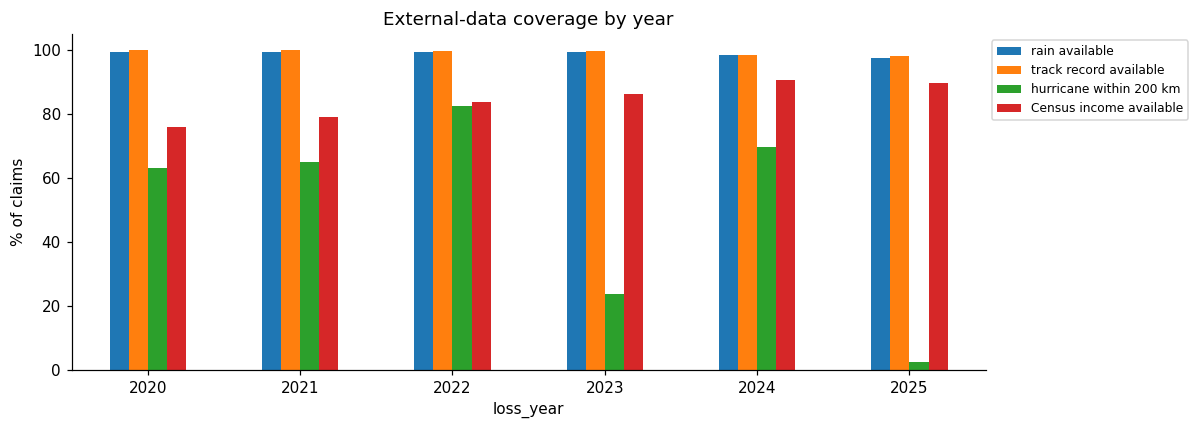

In [28]:
coverage=pd.DataFrame({'rain available':joined.rain_5d_mm.notna(),'track record available':joined.trk_dist_km.notna(),
                      'hurricane within 200 km':joined.trk_dist_km.le(200),'Census income available':joined.median_household_income.notna()})
display(coverage.mean().mul(100).round(2).to_frame('% of claims'))
join_audit=coverage.groupby(joined.loss_year).mean().mul(100)
display(join_audit.round(1));save_table(join_audit,'01_join_coverage')
join_audit.plot.bar(figsize=(11,4),title='External-data coverage by year');plt.ylabel('% of claims');plt.xticks(rotation=0)
plt.legend(fontsize=8,bbox_to_anchor=(1,1));plt.tight_layout();plt.show()

A missing track record differs from **no nearby hurricane**. The builder uses distance 5,000 km and wind zero when no Atlantic storm exists in its time window. A missing joined record stays missing. Census non-matches can reflect changing boundaries or unpublished estimates; year patterns alone cannot prove the exact cause. We do not assume an old and a new Census code refer to the same area.

Older caches were created after missing fallback coordinates were filled with a median location. We now discard weather values at these unknown locations. A value at a made-up location would create false precision. Valid block-group location matches are retained.

### 8.4 Understand the units and windows

| Input | Plain meaning | Important limit |
|---|---|---|
| `rain_lossday_mm` | Rain in two daily grids: loss day and next day | PRISM days end in the morning; this is a 48-hour proxy |
| `rain_3d_mm` | Rain from one day before to one day after loss | Local rain is not the same as flood-water depth |
| `rain_5d_mm` | Rain from three days before to one day after loss | Upstream rain outside this area can also matter |
| `rain_max1d_mm` | Wettest daily grid in that five-day window | Captures a short heavy burst |
| `rain_nb_max1d_mm`, `rain_nb_5d_mm` | Maximum nearby rain, within roughly 6 km | A nearby maximum can differ from rain at the house |
| `trk_dist_km` | Distance to the nearest storm-center point in the time window | 5,000 means no Atlantic storm in the window; missing means no usable joined value |
| `trk_wind_kt`, `trk_pres_mb` | Maximum storm wind in knots and central pressure | These describe the storm center, not conditions at the house |
| `trk_r34_km`, `trk_inside_r34` | Largest tropical-storm wind radius and a distance-based indicator | A circular approximation, not the exact wind footprint |
| `trk_maxwind_200km` | Strongest storm wind while the center was within 200 km | Does not measure surge height |
| `trk_right_side` | Whether the claim lies to the right of storm movement | A broad exposure clue; local coast shape is not included |
| `median_household_income` | Typical household income for the block group | Does not reveal the claimant's income |
| `median_home_value` | Median home value in the block group | Differs from the reported replacement cost of a claim building |
| `renter_share` | Rented units as a share of occupied units | An area summary, not the claimant's tenure |

Millimeters measure rain depth. Kilometers measure distance. The predictive models combine these inputs with policy and building features; they never use adjusted damage or payment as predictors of their own outcomes. The anomaly notebook is different: it studies completed claim records, so payment and damage are deliberate inputs.

### 8.5 Does matching select different claims?
The matched and unmatched Census groups can differ in year, place and building type. A successful join is not proof of a representative sample.

In [29]:
match=joined.median_household_income.notna()
display(joined.groupby(match).agg(claims=('id','size'),median_year=('loss_year','median'),
    Florida_share=('state',lambda s:s.eq('FL').mean()),condo_share=('occupancy',lambda s:s.eq('15').mean()),
    median_payment=('amountPaidOnBuildingClaim','median')))
print('Weather fallback location unavailable:',joined.rain_location.eq('location unavailable').sum())
print('Rain location methods:');display(joined.rain_location.value_counts(dropna=False).to_frame('claims'))

,claims,median_year,Florida_share,condo_share,median_payment
median_household_income,,,,,
False,41571,"2,022.000",0.451,0.073,"15,742.315"
True,235462,"2,023.000",0.569,0.056,"25,775.225"


Weather fallback location unavailable: 1826
Rain location methods:


,claims
rain_location,
block group,254020
rounded lat/lon,19776
location unavailable,1826
outside PRISM grid,948
NaN,463


**Decision.** Main predictive experiments retain missing matches with fitting-period imputation and flags. The income analysis reports its matched population separately. Older weather caches at an unknown median fallback location are discarded; invented locations would create false precision.

### 8.6 See the whole picture: how the four sources fit together
The picture below shows how one claim becomes one row in our working table. Each outside source is attached with a key (a value that identifies the same thing in two tables). If a key finds no match, the claim stays in the table and the new columns stay empty.

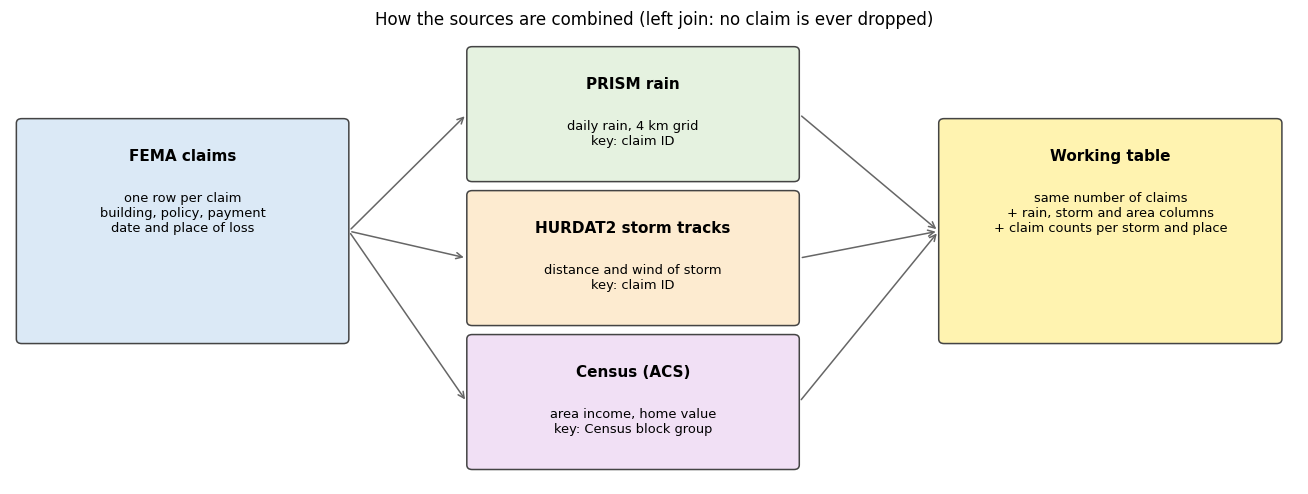

In [30]:
from matplotlib.patches import FancyBboxPatch
fig,ax=plt.subplots(figsize=(12,4.6));ax.set_xlim(0,12);ax.set_ylim(0,5);ax.axis('off')
def box(x,y,w,h,title,lines,color):
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.05',fc=color,ec='#444444',lw=1))
    ax.text(x+w/2,y+h-0.28,title,ha='center',va='top',fontsize=10,fontweight='bold')
    ax.text(x+w/2,y+h-0.75,'\n'.join(lines),ha='center',va='top',fontsize=8.5)
box(0.1,1.6,3.0,2.4,'FEMA claims',['one row per claim','building, policy, payment','date and place of loss'],'#dbe9f6')
box(4.3,3.4,3.0,1.4,'PRISM rain',['daily rain, 4 km grid','key: claim ID'],'#e5f2e0')
box(4.3,1.8,3.0,1.4,'HURDAT2 storm tracks',['distance and wind of storm','key: claim ID'],'#fdebd0')
box(4.3,0.2,3.0,1.4,'Census (ACS)',['area income, home value','key: Census block group'],'#f1e0f5')
box(8.7,1.6,3.1,2.4,'Working table',['same number of claims','+ rain, storm and area columns','+ claim counts per storm and place'],'#fff3b0')
for y_ in [4.1,2.5,0.9]:
    ax.annotate('',xy=(4.25,y_),xytext=(3.15,2.8),arrowprops=dict(arrowstyle='->',color='#666666'))
    ax.annotate('',xy=(8.65,2.8),xytext=(7.35,y_),arrowprops=dict(arrowstyle='->',color='#666666'))
ax.set_title('How the sources are combined (left join: no claim is ever dropped)',fontsize=11)
plt.tight_layout();plt.show()

### 8.7 One claim, followed through the join
Here is one real claim after the join. The first group of columns comes from FEMA. The other groups were added from the outside sources. This is the row that a model sees.

In [31]:
example_pool=joined[joined.floodEvent.eq('Hurricane Ian')&joined.rain_5d_mm.notna()&joined.trk_dist_km.notna()
                    &joined.median_household_income.notna()&joined.buildingDamageAmount.gt(0)&joined.occupancy.eq('11')]
one=example_pool.sample(1,random_state=SEED).iloc[0]
groups={'FEMA claim':['state','loss_year','floodEvent','occupancy_name','foundation_name','building_age','totalBuildingInsuranceCoverage','amountPaidOnBuildingClaim'],
        'PRISM rain':['rain_lossday_mm','rain_5d_mm','rain_max1d_mm'],
        'HURDAT2 storm':['trk_dist_km','trk_wind_kt','trk_pres_mb'],
        'Census area':['median_household_income','median_home_value','renter_share']}
example=pd.DataFrame([(g,c,one[c]) for g,cols in groups.items() for c in cols],columns=['source','column','value']).set_index(['source','column'])
display(example)

value
source        column                                       
FEMA claim    state                                      FL
              loss_year                                2022
              floodEvent                      Hurricane Ian
              occupancy_name                  single family
              foundation_name                          slab
              building_age                           48.493
              totalBuildingInsuranceCoverage    100,000.000
              amountPaidOnBuildingClaim         100,000.000
PRISM rain    rain_lossday_mm                       368.481
              rain_5d_mm                            377.740
              rain_max1d_mm                         298.602
HURDAT2 storm trk_dist_km                            22.843
              trk_wind_kt                           130.385
              trk_pres_mb                           940.769
Census area   median_household_income            78,403.000
              median_home_value                 246,100.000
              renter_share                            0.152

### 8.8 A fourth clue made from the claims themselves: claim counts
Rain, tracks and Census values describe the weather and the area. None of them says how many homes in one neighborhood were flooded. The claims table can tell us this directly. For each claim we count how many claims came from the **same block group, county and state in the same storm**. We use the *number* of claims only, never their payments.

These counts are known only after the claims arrive. Models that use them are therefore studies of past storms, not first-day forecasts. The plots below check whether each outside clue is linked to damage before we ask a model to use it.

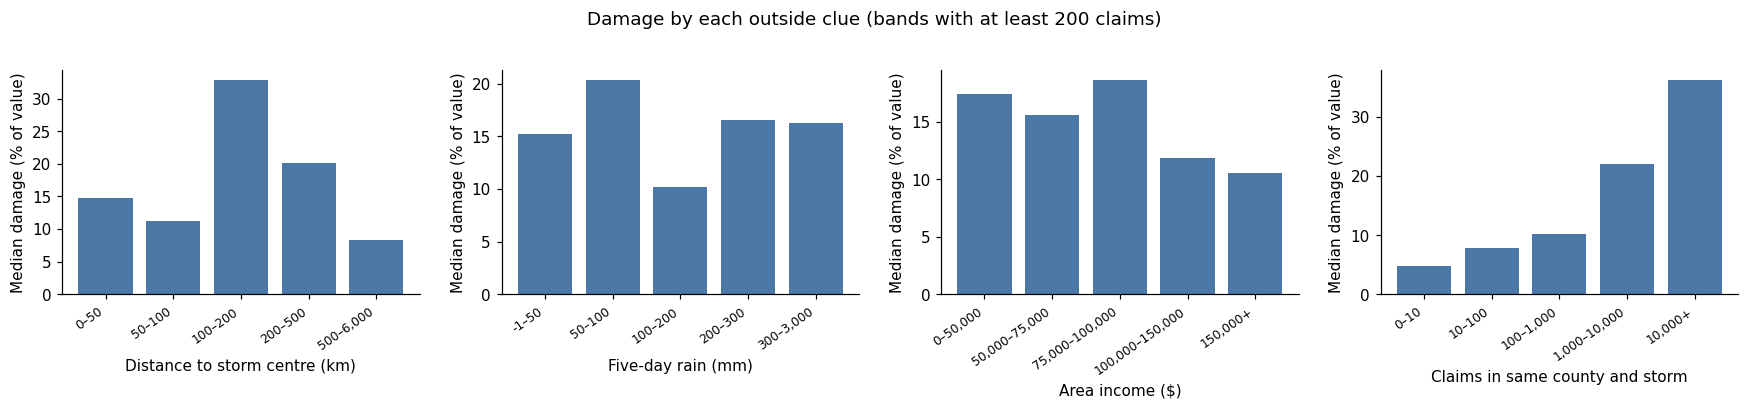

,Spearman link with damage
Distance to storm centre (km),-0.059
Five-day rain (mm),-0.011
Area income ($),-0.071
Claims in same county and storm,0.290


In [32]:
eda=joined[joined.damage_ratio.notna()].copy()
eda['county claims in storm']=np.expm1(eda.claims_county_storm)
panels=[('trk_dist_km','Distance to storm centre (km)',[0,50,100,200,500,6000]),
        ('rain_5d_mm','Five-day rain (mm)',[-1,50,100,200,300,3000]),
        ('median_household_income','Area income ($)',[0,50000,75000,100000,150000,1e7]),
        ('county claims in storm','Claims in same county and storm',[0,10,100,1000,10000,1e6])]
fig,axes=plt.subplots(1,4,figsize=(16,3.6))
for ax_,(col,label,edges) in zip(axes,panels):
    band=pd.cut(eda[col],edges)
    table=eda.groupby(band,observed=True).damage_ratio.agg(['median','size'])
    table=table[table['size']>=200]
    ax_.bar(range(len(table)),table['median']*100,color='#4c78a8')
    ax_.set_xticks(range(len(table)));ax_.set_xticklabels([f'{i.left:,.0f}–{i.right:,.0f}' if i.right<1e6 else f'{i.left:,.0f}+' for i in table.index],rotation=35,ha='right',fontsize=8)
    ax_.set(xlabel=label,ylabel='Median damage (% of value)')
plt.suptitle('Damage by each outside clue (bands with at least 200 claims)',y=1.02);plt.tight_layout();plt.show()
signal=pd.Series({label:eda[col].corr(eda.damage_ratio,method='spearman') for col,label,_ in panels}).to_frame('Spearman link with damage')
display(signal.round(3));save_table(signal,'01_source_signal')

**What combining the data gave us.** Claims alone tell us about the building and the policy. Rain and storm tracks add the weather. Census adds the neighborhood. Claim counts add a rough measure of how widely one storm flooded one area. Each clue is linked to damage, but only weakly, and the links point in different directions in different storms.

**What combining the data could not give us.** None of the sources measures the *depth of water inside a building*. This is the fact that decides most of the damage. We come back to this in notebooks 02 and 03, where it explains why prediction scores stay modest.

## 9. Explore the combined data before adding every column to a model
### 9.1 Do six rain features provide six different pieces of information?
Several windows use the same rainy days. Strong correlations suggest repeated information. Notebook 02 will test whether fewer columns or PCA can help, rather than selecting features using evaluation outcomes.

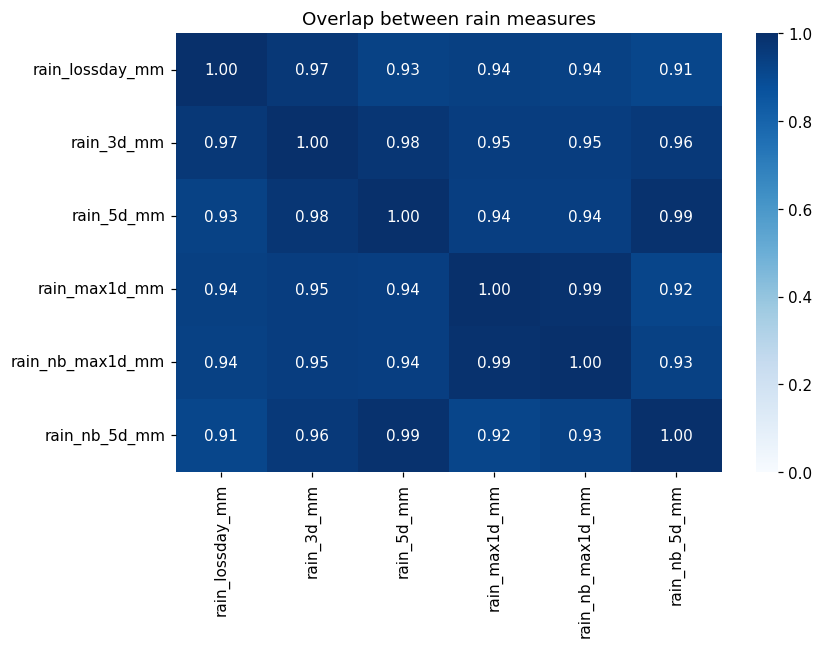

In [33]:
rain_columns=[c for c in RAIN if not c.endswith('_missing')]
plt.figure(figsize=(8,6));sns.heatmap(joined[rain_columns].corr(),vmin=0,vmax=1,annot=True,fmt='.2f',cmap='Blues')
plt.title('Overlap between rain measures');plt.tight_layout();plt.show()

### 9.2 Compare external exposure across the largest events
We look for a plausible explanation of weak prediction. A storm can produce high claims with modest local rain, so rain alone cannot describe every flood process. We cannot prove surge caused an individual loss from this table.

In [34]:
top_events=joined.floodEvent.value_counts().head(8).index
storm_eda=joined[joined.floodEvent.isin(top_events)].groupby('floodEvent').agg(claims=('id','size'),
    median_payment=('amountPaidOnBuildingClaim','median'),median_damage_ratio=('damage_ratio','median'),
    rain_5d_mm=('rain_5d_mm','median'),track_distance_km=('trk_dist_km','median'),
    income=('median_household_income','median'),census_match=('median_household_income',lambda s:s.notna().mean()))
display(storm_eda.sort_values('claims',ascending=False).round(2));save_table(storm_eda,'01_combined_storm_summary')

,claims,median_payment,median_damage_ratio,rain_5d_mm,track_distance_km,income,census_match
floodEvent,,,,,,,
Hurricane Helene,58090,"83,740.570",0.380,55.600,184.280,"95,455.000",0.930
Hurricane Ian,48824,"45,550.870",0.240,163.790,34.160,"90,938.000",0.840
Hurricane Ida,28318,"17,673.790",0.100,196.660,49.440,"90,000.000",0.800
Hurricane Milton,21675,"21,733.050",0.160,200.240,71.120,"80,577.000",0.870
Hurricane Sally,8120,"8,804.240",0.050,403.220,24.710,"93,000.000",0.740
Hurricane Idalia,5522,"55,889.290",0.330,76.770,164.100,"85,469.000",0.870
Hurricane Eta,3677,"12,839.540",0.080,185.850,122.980,"96,053.000",0.840
April Florida Flooding,3443,"51,471.330",0.260,617.590,"5,000.000","83,173.000",0.830


### 9.3 A national relationship can hide different event relationships
We compare rain and damage ratio within events. We use a sample for the plot, not for the reported event table. These are descriptive relationships; adjusted damage is not an input to its own predictive model.

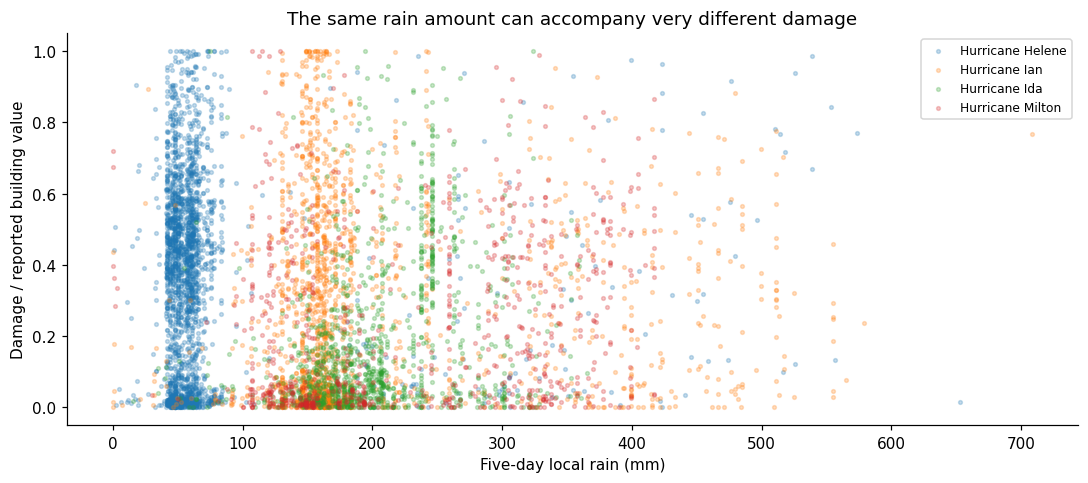

,claims,Spearman rain–damage ratio
event,,
April Florida Flooding,2992,0.245
Hurricane Eta,2967,-0.184
Hurricane Helene,47453,0.027
Hurricane Ian,35328,0.052
Hurricane Ida,23128,0.225
Hurricane Idalia,4629,-0.067
Hurricane Milton,15665,0.175
Hurricane Sally,6766,0.047


In [35]:
known=joined[joined.damage_ratio.notna()&joined.rain_5d_mm.notna()]
sample=known[known.floodEvent.isin(top_events[:4])].sample(min(6000,len(known[known.floodEvent.isin(top_events[:4])])),random_state=SEED)
fig,ax=plt.subplots(figsize=(10,4.5))
for event,g in sample.groupby('floodEvent'):
    ax.scatter(g.rain_5d_mm,g.damage_ratio,s=6,alpha=.25,label=event)
ax.set(xlabel='Five-day local rain (mm)',ylabel='Damage / reported building value',title='The same rain amount can accompany very different damage')
ax.legend(fontsize=8);plt.tight_layout();plt.show()
rows=[]
for event,g in known[known.floodEvent.isin(top_events)].groupby('floodEvent'):
    rows.append({'event':event,'claims':len(g),'Spearman rain–damage ratio':g.rain_5d_mm.corr(g.damage_ratio,method='spearman')})
display(pd.DataFrame(rows).set_index('event').round(3))

### 9.4 Neighborhood income is context, not claimant income
We show claims across income ranges and the change in damage and cover. These groups contain equal numbers of Census areas with published income, not equal exposure to flooding. We cannot infer insurance access from a 20% reference line alone.

,claims,median_ratio,median_building_value,Florida_share
median_household_income,,,,
Q1 lowest,31748,0.171,"161,597.000",0.472
Q2,43913,0.169,"174,315.000",0.524
Q3,48799,0.173,"199,690.000",0.567
Q4,56754,0.143,"222,040.000",0.613
Q5 highest,54248,0.106,"270,252.000",0.617


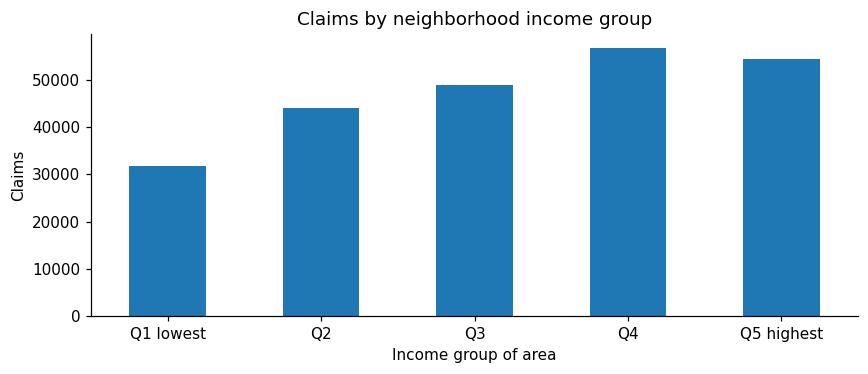

In [36]:
acs=pd.read_parquet(DATA/'acs_blockgroups.parquet')
edges=acs.median_household_income.quantile([0,.2,.4,.6,.8,1]).to_numpy();edges[0],edges[-1]=-np.inf,np.inf
income_group=pd.cut(joined.median_household_income,edges,labels=['Q1 lowest','Q2','Q3','Q4','Q5 highest'])
income_eda=joined.groupby(income_group,observed=True).agg(claims=('id','size'),
    median_ratio=('damage_ratio','median'),median_building_value=('buildingPropertyValue','median'),
    Florida_share=('state',lambda s:s.eq('FL').mean()))
display(income_eda.round(3));save_table(income_eda,'01_income_context')
income_eda.claims.plot.bar(figsize=(8,3.5),title='Claims by neighborhood income group')
plt.ylabel('Claims');plt.xlabel('Income group of area');plt.xticks(rotation=0);plt.tight_layout();plt.show()

## 10. Define the next steps before looking at later outcomes
Our main regression target is positive building payment. The classification target is damage above a threshold calculated from fitting years. Clustering describes buildings, then compares severity afterwards.

**Development:** fit 2020–2021 and compare on 2022–2023. **Later evaluation:** refit the frozen choice on 2020–2023 and evaluate 2024–2025. Earlier project versions already explored these years, so this is not a new external test.

In [37]:
thresholds=pd.Series({'development cutoff: 2020–2021':df.loc[df.loss_year.le(2021),'buildingDamageAmount'].quantile(.8),
                      'later-evaluation cutoff: 2020–2023':df.loc[df.loss_year.le(2023),'buildingDamageAmount'].quantile(.8)})
display(thresholds.to_frame('80th percentile damage $').round(0))
flow=pd.DataFrame({'question':['payment','large-loss label','damage-ratio profiles'],
                   'eligible claims':[df.amountPaidOnBuildingClaim.gt(0).sum(),df.buildingDamageAmount.notna().sum(),df.damage_ratio.notna().sum()],
                   'do not fill':['missing payment','missing damage','missing or inconsistent value ratio']})
display(flow)

,80th percentile damage $
development cutoff: 2020–2021,"57,923.000"
later-evaluation cutoff: 2020–2023,"83,893.000"


,question,eligible claims,do not fill
0,payment,212966,missing payment
1,large-loss label,246461,missing damage
2,damage-ratio profiles,217034,missing or inconsistent value ratio


### 10.1 Keep and discard ledger

| Observation | Decision | Where we check it next |
|---|---|---|
| Dropping every blank destroys the sample | Keep question-specific populations; estimate predictors inside fitting pipelines | 02 and 03 |
| Some redacted records match across different IDs | Retain unique IDs; flag similarity | 10 |
| A few real large buildings stretch dollar scales | Compare raw/log models and coverage-share models | 02 |
| Inspection fields correlate with payment | Exclude them from early predictors | 02 and 03 |
| Claims from a few storms dominate | Compare row, event and chronological validation | 02–04 |
| Rain windows overlap | Test feature selection and PCA; do not assume more columns help | 02 and 04 |
| Added sources have incomplete or approximate locations | Report coverage and missingness effects | 09 and 10 |
| Claims lack stable building histories | Do not invent property sequences | 11 |
| Outside sources describe weather and areas, not water depth | Add claim counts per storm and place as a rough flood-spread clue; label it retrospective | 02 and 03 |

**Next:** notebook 02 starts with constant predictions, then a linear model and tree models. Each new step must explain what it adds. The question is not “how many algorithms can we run?” It is “what did this comparison teach us?”

### Result in plain English

The joins keep every retained claim ID and make missing external matches visible. The EDA checks field meanings, missingness, unusual values, time, place and preparation choices. Rain and tracks support prediction, cluster, elevation and anomaly checks; Census supports neighborhood comparisons. These sources add event and neighborhood context, but they do not measure flood depth at each house. Different claims, locations and reporting periods make this a study of observed insurance claims, not all buildings exposed to flooding.